In [6]:
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
# mnist 데이터셋 로드
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [3]:
x_train.shape, x_test.shape

((60000, 28, 28), (10000, 28, 28))

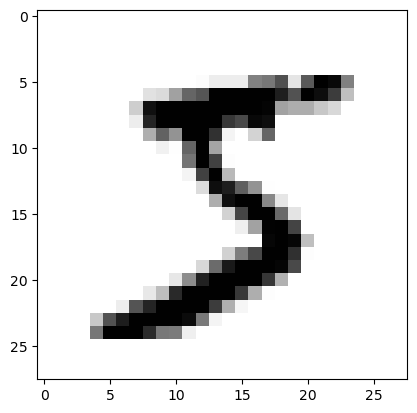

In [4]:
plt.imshow(x_train[0], cmap = "gray_r")
plt.show()

In [5]:
y_train[0]

5

In [7]:
np.unique(y_train, return_counts = True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8),
 array([5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949],
       dtype=int64))

In [9]:
np.min(x_test), np.max(x_test)

(0, 255)

In [10]:
x_train.shape

(60000, 28, 28)

In [11]:
scaled_train = x_train.reshape(-1, 28, 28, 1) / 255
scaled_test = x_test.reshape(-1, 28, 28, 1) / 255

In [12]:
scaled_train, scaled_val, y_train, y_val = train_test_split(scaled_train, y_train, test_size = 0.2,
                                                            stratify = y_train, random_state = 26)

In [13]:
scaled_train.shape, scaled_val.shape, y_train.shape, y_val.shape

((48000, 28, 28, 1), (12000, 28, 28, 1), (48000,), (12000,))

# 합성곱 신경망 설정

In [17]:
model = keras.Sequential()
model.add(keras.Input(shape = (28, 28, 1)))
model.add(keras.layers.Conv2D(32, kernel_size = 3, activation = "relu", padding = "same"))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Conv2D(64, kernel_size = 3, activation = "relu", padding = "same"))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(100, activation = "relu"))
model.add(keras.layers.Dropout(0.4))
model.add(keras.layers.Dense(10, activation = "softmax"))

In [18]:
model.compile(loss = "sparse_categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [19]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │         313,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 333,526 (1.27 MB)

 Trainable params: 333,526 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [21]:
history = model.fit(scaled_train, y_train, validation_data = (scaled_val, y_val), epochs = 40,
                    callbacks = [es_cb], batch_size = 32)

Epoch 1/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.8554 - loss: 0.4579 - val_accuracy: 0.9827 - val_loss: 0.0580
Epoch 2/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9761 - loss: 0.0828 - val_accuracy: 0.9862 - val_loss: 0.0458
Epoch 3/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9822 - loss: 0.0572 - val_accuracy: 0.9887 - val_loss: 0.0400
Epoch 4/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9849 - loss: 0.0477 - val_accuracy: 0.9913 - val_loss: 0.0330
Epoch 5/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9889 - loss: 0.0373 - val_accuracy: 0.9913 - val_loss: 0.0331
Epoch 6/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9907 - loss: 0.0285 - val_accuracy: 0.9908 - val_loss: 0.0401
Epoch 7/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9911 - loss: 0.0276 - val_accuracy: 0.9914 - val_loss: 0.0383
Epoch 8/40
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 21s 14ms/step - accuracy: 0.9927 -

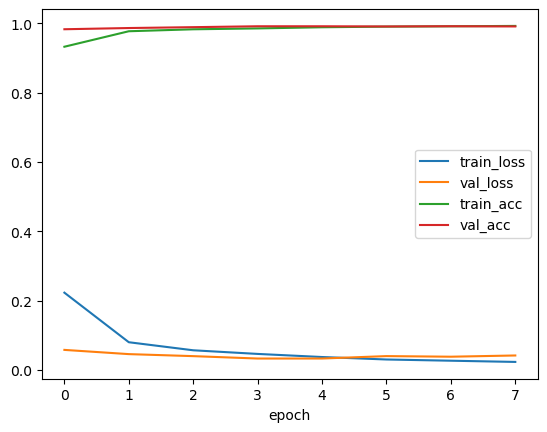

In [22]:
plt.figure()

plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

In [23]:
model.evaluate(scaled_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9883 - loss: 0.0349


[0.028898019343614578, 0.9904999732971191]

In [24]:
preds = model.predict(scaled_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [25]:
preds.shape

(10000, 10)

In [26]:
pred_arr = np.argmax(preds, axis = 1)

In [28]:
y_test[pred_arr != y_test]

array([3, 4, 6, 8, 5, 7, 4, 3, 8, 6, 7, 4, 6, 7, 9, 4, 9, 7, 8, 7, 8, 4,
       9, 8, 9, 1, 6, 9, 4, 6, 1, 9, 9, 4, 3, 5, 6, 8, 3, 3, 5, 9, 6, 6,
       8, 1, 7, 6, 9, 6, 5, 4, 7, 4, 7, 6, 4, 8, 2, 8, 7, 3, 8, 1, 3, 9,
       8, 3, 9, 4, 7, 3, 3, 9, 9, 9, 9, 9, 7, 0, 8, 0, 8, 4, 7, 7, 7, 9,
       9, 2, 6, 9, 5, 5, 4], dtype=uint8)

In [29]:
x_match = []

for idx, item in enumerate(pred_arr):
    if item != y_test[idx]:
        x_match.append(idx)

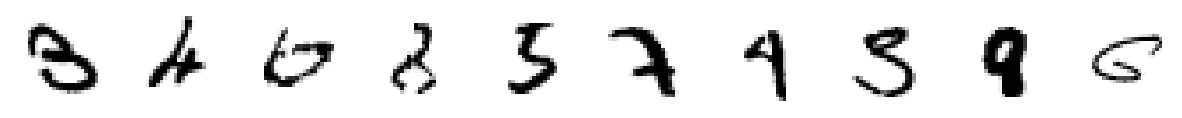

In [30]:
fig, axs = plt.subplots(1, 10, figsize = (15, 15))

for i, item in enumerate(x_match[:10]):
    axs[i].imshow(x_test[item], cmap = "gray_r")
    axs[i].axis("off")
plt.show()

In [31]:
pred_arr[x_match[:10]]

array([5, 2, 0, 2, 3, 2, 9, 5, 9, 5], dtype=int64)

In [32]:
y_test[x_match[:10]]

array([3, 4, 6, 8, 5, 7, 4, 3, 8, 6], dtype=uint8)